<a href="https://colab.research.google.com/github/bilalh04-coder/penguin_species_id/blob/main/Another_copy_of_H04_P51_Bilal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay)
from sklearn.neighbors import KNeighborsClassifier
import warnings; warnings.filterwarnings("ignore")
print("All libraries loaded!")


All libraries loaded!


In [ ]:
df = pd.read_csv("penguins_size.csv")
print(df.shape)      # (rows, columns)
df.head()

(344, 7)


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [ ]:
df.info()                   # column names, types, non-null counts
df.describe()               # min, max, mean of number columns
print(df.isnull().sum())    # missing values in each column
print("Duplicates:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB
species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64
Duplicates: 0


In [ ]:
TARGET = "species"
print(df[TARGET].value_counts())                  # how many rows in each class
print(df[TARGET].value_counts(normalize=True))    # same, as percentages

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
species
Adelie       0.441860
Gentoo       0.360465
Chinstrap    0.197674
Name: proportion, dtype: float64


In [ ]:
df = df.drop_duplicates()

# Drop ID / name / leaking columns (write the real column names from your data)
# df = df.drop(columns=["id_column", "name_column"])

for col in df.columns:
    if col == TARGET: continue
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())     # number column -> median
    else:
        df[col] = df[col].fillna(df[col].mode()[0])    # text column -> most common value
df = df.dropna(subset=[TARGET])

print(df.isnull().sum().sum(), "missing values left")
print(df.shape)

0 missing values left
(344, 7)


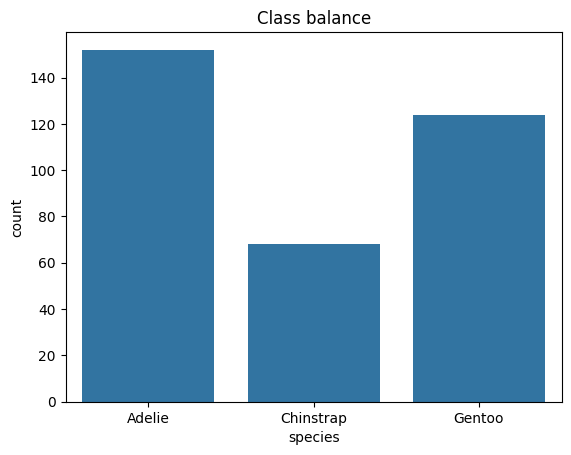

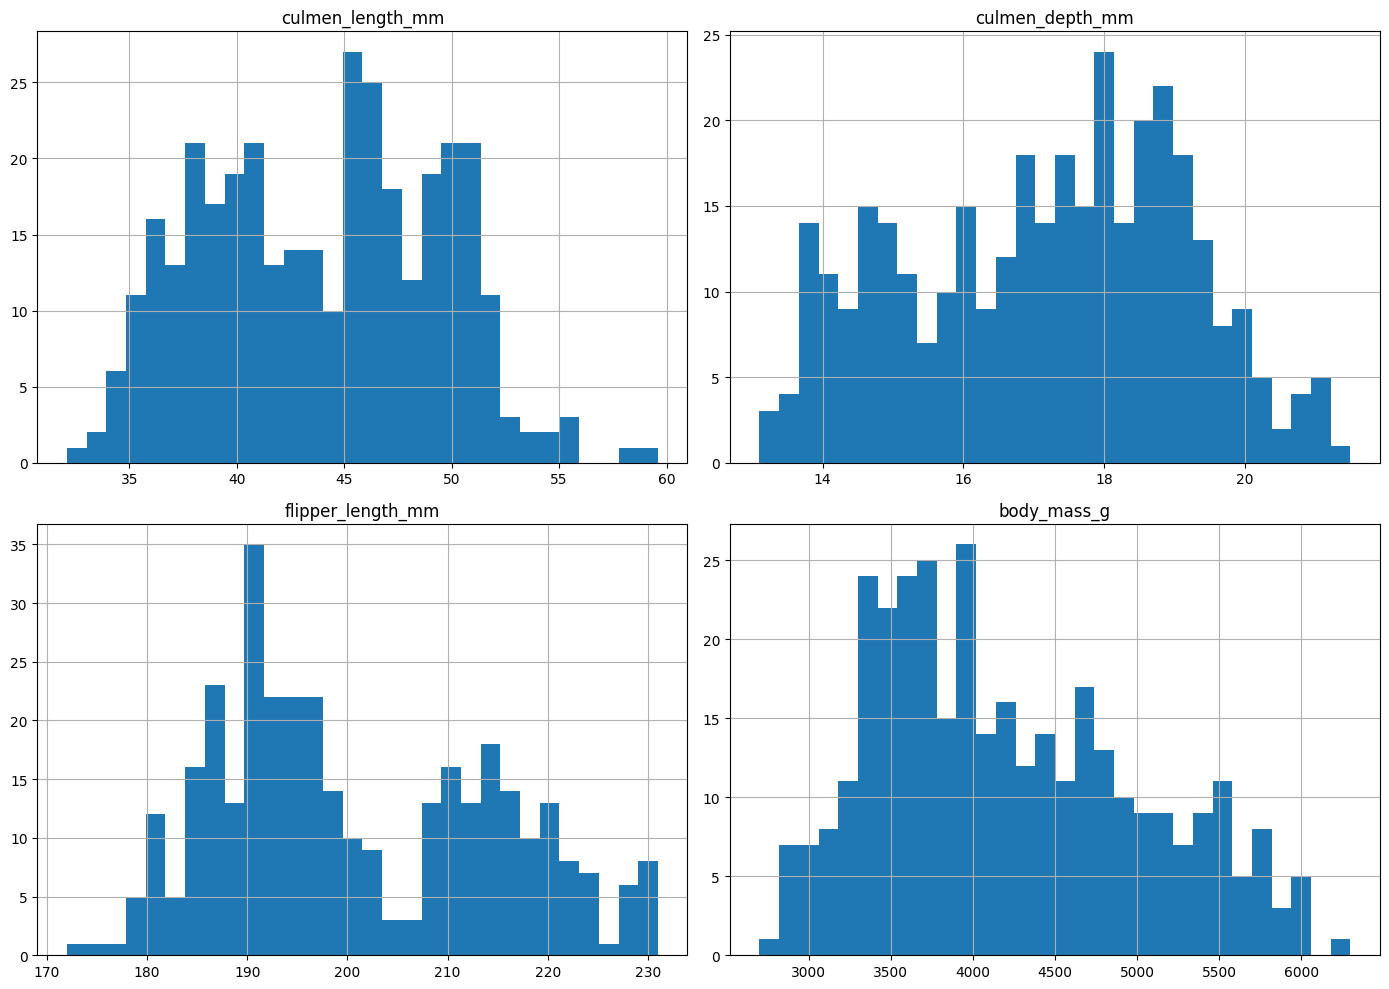

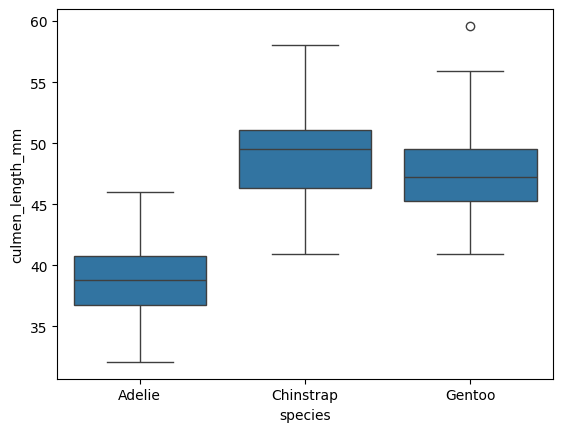

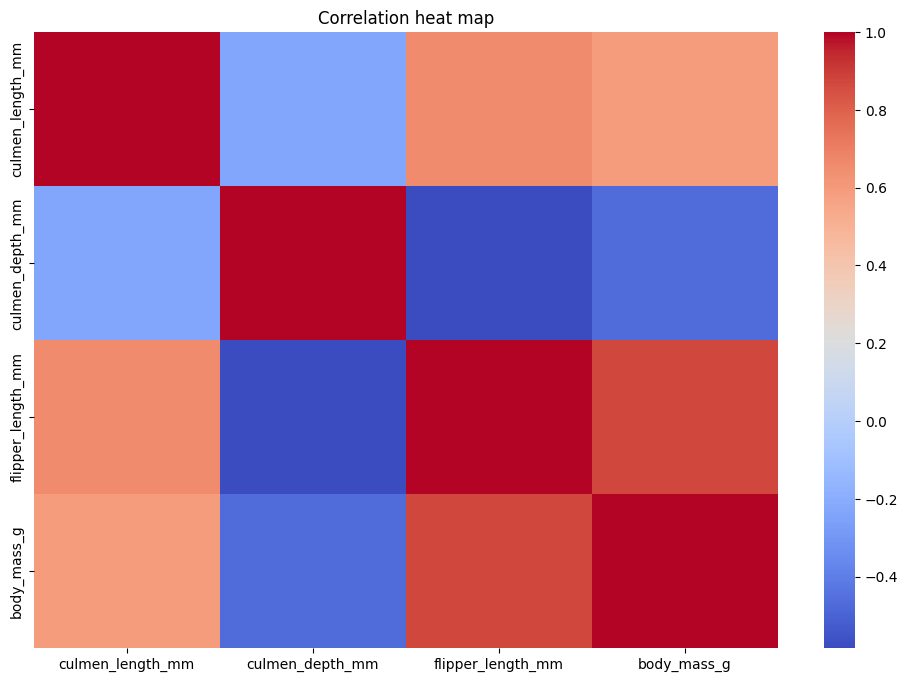

In [ ]:
sns.countplot(x=df[TARGET]); plt.title("Class balance"); plt.show()

num_cols = df.select_dtypes(include="number").columns
df[num_cols].hist(figsize=(14, 10), bins=30); plt.tight_layout(); plt.show()

# Box plot of one important numeric column by class (change the column name)
sns.boxplot(x=df[TARGET], y=df[num_cols[0]]); plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df[num_cols].corr(), cmap="coolwarm"); plt.title("Correlation heat map"); plt.show()

In [ ]:
# 1) NEW FEATURE: create at least one new column that makes sense for your data
#    example: df["new_feature"] = df["column_a"] / (df["column_b"] + 1)
#    (change the column names to real columns from YOUR dataset)

# 2) Separate X (inputs) and y (target)
X = df.drop(columns=[TARGET])
le_y = LabelEncoder()
y = le_y.fit_transform(df[TARGET])
print("Classes:", list(le_y.classes_))     # class 0, class 1, ...

# 3) ENCODING: turn text columns into numbers (one-hot encoding)
X = pd.get_dummies(X, drop_first=True)
print(X.shape)

# 4) FEATURE SELECTION (filter method): keep the most useful columns
from sklearn.feature_selection import SelectKBest, f_classif
k = min(15, X.shape[1])
selector = SelectKBest(f_classif, k=k).fit(X, y)
scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
print(scores.head(20))
X = X[scores.head(k).index]
feature_names = list(X.columns)
print("Selected:", feature_names)

Classes: ['Adelie', 'Chinstrap', 'Gentoo']
(344, 8)
flipper_length_mm    576.015479
culmen_length_mm     405.095443
culmen_depth_mm      354.025923
body_mass_g          337.587351
island_Dream         211.791494
island_Torgersen      49.484651
sex_FEMALE             0.091002
sex_MALE               0.053889
dtype: float64
Selected: ['flipper_length_mm', 'culmen_length_mm', 'culmen_depth_mm', 'body_mass_g', 'island_Dream', 'island_Torgersen', 'sex_FEMALE', 'sex_MALE']


In [ ]:
# If your data has more than 20,000 rows, first take a sample (SVM/KNN are slow on big data):
# df = df.sample(20000, random_state=42)   <- do this BEFORE Step 7 and re-run Step 7

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

# SCALING (must for K-Nearest Neighbours (KNN)). Fit ONLY on train data, then apply to test.
X_train_raw, X_test_raw = X_train.copy(), X_test.copy()   # keep unscaled copy
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

(275, 8) (69, 8)


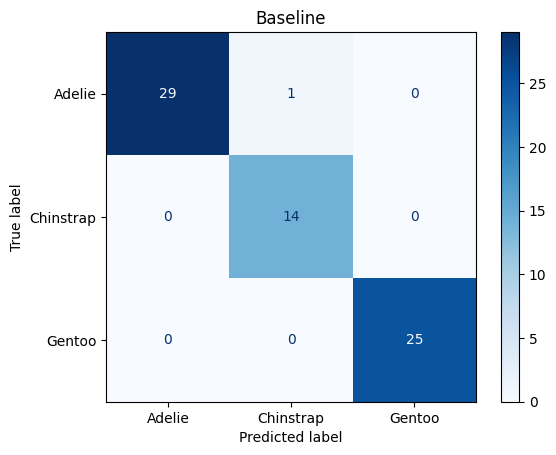

              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       0.93      1.00      0.97        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.98      0.99      0.98        69
weighted avg       0.99      0.99      0.99        69

{'Setting': 'Baseline', 'Accuracy': 0.9855072463768116, 'Precision': 0.9777777777777779, 'Recall': 0.9888888888888889, 'F1': 0.9828560296123126, 'Specificity': np.float64(0.993939393939394), 'AUC': np.float64(1.0)}


In [ ]:
results = []     # every setting you try is stored here

def evaluate(name, model, show=False):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    spec_list = []
    for i in range(len(cm)):
        tn = cm.sum() - cm[i, :].sum() - cm[:, i].sum() + cm[i, i]
        fp = cm[:, i].sum() - cm[i, i]
        spec_list.append(tn / (tn + fp))
    spec = np.mean(spec_list)
    try:
        proba = model.predict_proba(X_test)
        auc = roc_auc_score(y_test, proba, multi_class="ovr", average="macro")
    except Exception:
        auc = None
    row = {"Setting": name,
           "Accuracy": accuracy_score(y_test, y_pred),
           "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
           "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
           "F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
           "Specificity": spec, "AUC": auc}
    if show:
        ConfusionMatrixDisplay(cm, display_labels=le_y.classes_).plot(cmap="Blues")
        plt.title(name); plt.show()
        print(classification_report(y_test, y_pred, target_names=[str(c) for c in le_y.classes_]))

    print(row)
    return row

# BASELINE: your model with default settings
model = KNeighborsClassifier(n_neighbors=5)
results.append(evaluate("Baseline", model, show=True))

{'Setting': 'k=1', 'Accuracy': 0.9855072463768116, 'Precision': 0.9777777777777779, 'Recall': 0.9888888888888889, 'F1': 0.9828560296123126, 'Specificity': np.float64(0.993939393939394), 'AUC': np.float64(0.9914141414141414)}
{'Setting': 'k=3', 'Accuracy': 0.9855072463768116, 'Precision': 0.9777777777777779, 'Recall': 0.9888888888888889, 'F1': 0.9828560296123126, 'Specificity': np.float64(0.993939393939394), 'AUC': np.float64(0.9914141414141414)}
{'Setting': 'k=5', 'Accuracy': 0.9855072463768116, 'Precision': 0.9777777777777779, 'Recall': 0.9888888888888889, 'F1': 0.9828560296123126, 'Specificity': np.float64(0.993939393939394), 'AUC': np.float64(1.0)}
{'Setting': 'k=7', 'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0, 'Specificity': np.float64(1.0), 'AUC': np.float64(1.0)}
{'Setting': 'k=9', 'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0, 'Specificity': np.float64(1.0), 'AUC': np.float64(1.0)}
{'Setting': 'k=11', 'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0

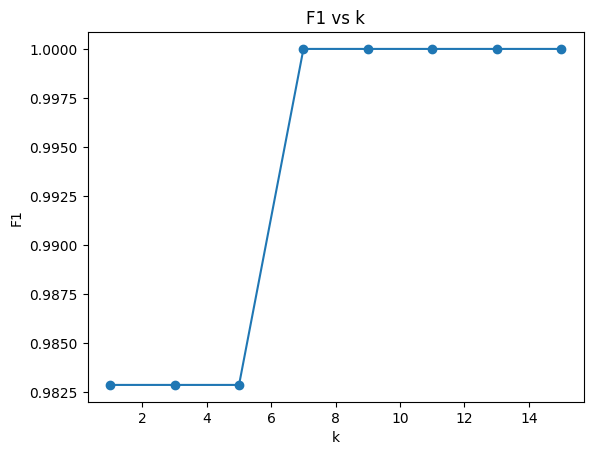

{'Setting': 'k=7, euclidean', 'Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0, 'Specificity': np.float64(1.0), 'AUC': np.float64(1.0)}
{'Setting': 'k=7, manhattan', 'Accuracy': 0.9855072463768116, 'Precision': 0.9777777777777779, 'Recall': 0.9888888888888889, 'F1': 0.9828560296123126, 'Specificity': np.float64(0.993939393939394), 'AUC': np.float64(1.0)}
Accuracy WITHOUT scaling: 0.7536231884057971


In [ ]:
# A) Try different k values
ks = [1, 3, 5, 7, 9, 11, 13, 15]
f1s = []
for k in ks:
    r = evaluate(f"k={k}", KNeighborsClassifier(n_neighbors=k))
    results.append(r); f1s.append(r["F1"])
plt.plot(ks, f1s, marker="o"); plt.xlabel("k"); plt.ylabel("F1"); plt.title("F1 vs k"); plt.show()

# B) Distance metric (use your best k)
best_k = ks[int(np.argmax(f1s))]
for m in ["euclidean", "manhattan"]:
    results.append(evaluate(f"k={best_k}, {m}", KNeighborsClassifier(n_neighbors=best_k, metric=m)))

# C) Without scaling (to show why scaling matters)
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_raw, y_train)
print("Accuracy WITHOUT scaling:", accuracy_score(y_test, knn.predict(X_test_raw)))

,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,Baseline,0.986,0.978,0.989,0.983,0.994,1.000
1,k=1,0.986,0.978,0.989,0.983,0.994,0.991
2,k=3,0.986,0.978,0.989,0.983,0.994,0.991
3,k=5,0.986,0.978,0.989,0.983,0.994,1.000
4,k=7,1.000,1.000,1.000,1.000,1.000,1.000
5,k=9,1.000,1.000,1.000,1.000,1.000,1.000
6,k=11,1.000,1.000,1.000,1.000,1.000,1.000
7,k=13,1.000,1.000,1.000,1.000,1.000,1.000
8,k=15,1.000,1.000,1.000,1.000,1.000,1.000
9,"k=7, euclidean",1.000,1.000,1.000,1.000,1.000,1.000


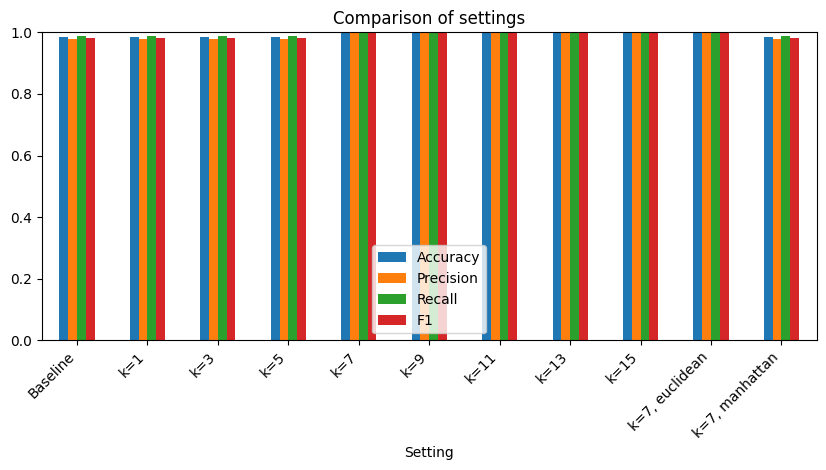

Best setting by Accuracy: k=11


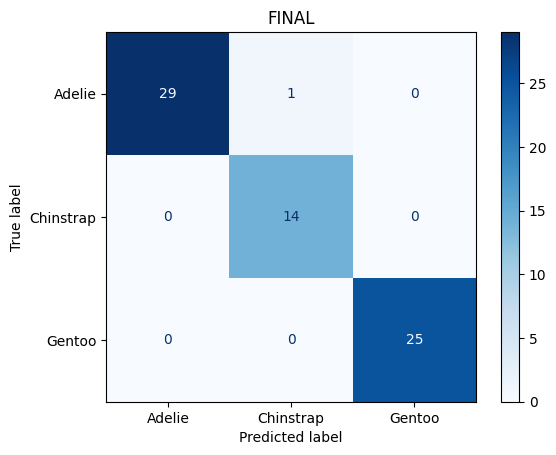

              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       0.93      1.00      0.97        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.98      0.99      0.98        69
weighted avg       0.99      0.99      0.99        69

{'Setting': 'FINAL', 'Accuracy': 0.9855072463768116, 'Precision': 0.9777777777777779, 'Recall': 0.9888888888888889, 'F1': 0.9828560296123126, 'Specificity': np.float64(0.993939393939394), 'AUC': np.float64(1.0)}


{'Setting': 'FINAL',
 'Accuracy': 0.9855072463768116,
 'Precision': 0.9777777777777779,
 'Recall': 0.9888888888888889,
 'F1': 0.9828560296123126,
 'Specificity': np.float64(0.993939393939394),
 'AUC': np.float64(1.0)}

In [ ]:
res = pd.DataFrame(results).round(3)
display(res)                                    # the comparison table for your report

res.set_index("Setting")[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(10, 4))
plt.title("Comparison of settings"); plt.ylim(0, 1); plt.xticks(rotation=45, ha="right"); plt.show()

best = res.sort_values("Accuracy", ascending=False).iloc[0]
print("Best setting by Accuracy:", best["Setting"])

# FINAL MODEL: write the best setting here (example below), then show its full result
final_model = KNeighborsClassifier(n_neighbors=5)      # <- put your best setting inside ( )
evaluate("FINAL", final_model, show=True)

In [ ]:
# Start from 3 real rows and change some values to make 3 NEW realistic inputs
new = X.iloc[[0, 1, 2]].copy()
# example: new.iloc[0, 0] = 50       <- change values in your own way and explain why
display(new)
pred = final_model.predict(scaler.transform(new))
print("Predictions:", le_y.inverse_transform(pred))


,flipper_length_mm,culmen_length_mm,culmen_depth_mm,body_mass_g,island_Dream,island_Torgersen,sex_FEMALE,sex_MALE
0,181.0,39.1,18.7,3750.0,False,True,False,True
1,186.0,39.5,17.4,3800.0,False,True,True,False
2,195.0,40.3,18.0,3250.0,False,True,True,False


Predictions: ['Adelie' 'Adelie' 'Adelie']


## **Project Conclusion – Penguin Species Classification Using KNN**

This project uses the Palmer Penguins dataset to classify penguins into three species: Adelie, Chinstrap, and Gentoo.

The dataset contains 344 records and 7 original columns.

The project includes:

1. Data loading and exploration.
2. Data cleaning and missing value treatment.
3. Exploratory Data Analysis (EDA).
4. Data visualization.
5. Feature engineering and selection.
6. Train-test splitting.
7. Feature scaling.
8. K-Nearest Neighbors (KNN) classification.
9. Model tuning and evaluation.
10. Penguin species prediction.

The baseline KNN model achieved approximately 98.55% accuracy on the test dataset. Model tuning was performed using different K values and distance metrics.

The project demonstrates how machine learning can classify penguin species using physical measurements and other features.